In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


## Adding W&B API key

In [2]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
WB_KEY = user_secrets.get_secret("WANDB_API_KEY")
os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")


In [3]:
import wandb

wandb.login(key=WB_KEY)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

In [ ]:
!pip install sentence-transformers

In [ ]:
import wandb

print("Initializing wandb")

run = wandb.init(
    entity="ambatwar-iitm",
    project="dlgenai-t226",
    name="mcq-solver-full-pipeline",
    group="full-pipeline-runs",
    job_type="full_pipeline",
    tags=["all_models", "training_curves"],
    config={
        "task": "smart-mcq-solver-challenge",
    },
)

print("W&B run:", run.url)
print("This run tracks step-by-step training curves and artifacts for the whole notebook.")
print("A separate run is logged per model near the end (Step 13) so all models can be")
print("compared side by side in the W&B UI (Runs table / bar chart / parallel coordinates).")


## Step 1 - Setup & environment check

In [6]:
import sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import transformers

import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0])
print("Platform    :", platform.system(), platform.release())
print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("PyTorch     :", torch.__version__)
print("Transformers:", transformers.__version__)
print("-" * 45)

# The device we'll use for all tensor computation.
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device      :", device)
if device == "cuda":
    print("GPU         :", torch.cuda.get_device_name(0))
    print("VRAM (GB)   :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
print("-" * 45)

# Confirm the dataset files exist (paths are relative to this notebook's folder).
DATA_DIR = Path("/kaggle/input/competitions/smart-mcq-solver-challenge")
for fname in ["train.csv", "test.csv", "sample_submission.csv"]:
    fpath = DATA_DIR / fname
    status = "FOUND   " if fpath.exists() else "MISSING!"
    print(f"{fname:22s} {status} -> {fpath}")

#import os
#from kaggle_secrets import UserSecretsClient
#os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

Python      : 3.12.13
Platform    : Linux 6.12.90+
NumPy       : 2.4.6
Pandas      : 2.3.3
PyTorch     : 2.10.0+cu128
Transformers: 5.0.0
---------------------------------------------
Device      : cuda
GPU         : Tesla T4
VRAM (GB)   : 15.64
---------------------------------------------
train.csv              FOUND    -> /kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
test.csv               FOUND    -> /kaggle/input/competitions/smart-mcq-solver-challenge/test.csv
sample_submission.csv  FOUND    -> /kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv


## Step 2 - Reading input

In [7]:
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
sample_sub = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv")

train.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [8]:
test.head()

,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...
3,4,What is the significance of the redshift-dista...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...,Observations of the redshift-distance relation...
4,5,What is the Landau-Lifshitz-Gilbert equation u...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...,The Landau-Lifshitz-Gilbert equation is a diff...


In [9]:
train.describe()

,id
count,2000.000000
mean,1000.500000
std,577.494589
min,1.000000
25%,500.750000
50%,1000.500000
75%,1500.250000
max,2000.000000


In [10]:
# check the shape of train and test
print(train.shape)
print(test.shape)
print(sample_sub.shape)

(2000, 8)
(500, 7)
(500, 2)


In [11]:
print("train columns:", list(train.columns))
print("test columns :", list(test.columns))
print()

print("Missing values per column (train):")
print(train.isna().sum().to_string())
print()

train columns: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer']
test columns : ['id', 'prompt', 'A', 'B', 'C', 'D', 'E']

Missing values per column (train):
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0



In [12]:
def show_question(row, show_answer=True):
    """ Preety-print a single question row so it is easy to read. """
    print("PROMPT:")
    print("  " + str(row["prompt"]))
    print()
    for opt in ["A", "B", "C", "D", "E"]:
        print(f"  {opt}) {row[opt]}")
    if show_answer and "answer" in row.index:
        print()
        print(" CORRECT ANSWER:", row["answer"])

print("=" * 80)
print("ONE EXAMPLE FROM THE TRAINING SET")
print("=" * 80)
show_question(train.iloc[0])
print("=" *80)

ONE EXAMPLE FROM THE TRAINING SET
PROMPT:
  Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options.

  A) Martin Heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. The relationship to the past involves acknowledging it as a historical era, and the relationship to the future involves creating a world that will endure beyond one's own time.
  B) Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, and the relationship to the future involves anticipating a potential possibility, task, or engagement.
  C) Martin Heidegger does not believe in the existence of time or that it has any effect on human consciousness. The relationship to the past and the future is insignificant, and human existence is solely based on the present.
  D) Ma

## Step 3 - Explore the data (EDA)

EDA stands for Exploratory Data Analysis. Before any modeling we ask simple questions about the data, because the answers change every later decision:

1. **How are the correct answers distributed across A, B, C, D, E?**
   - If they are roughly equal, there is no shortcut: a constant guess like "A B C" cannot beat chance.
   - If one letter is much more common, even a simple baseline can exploit that bias.
2. **How long are the prompts and options (in words)?**
   - This sets the maximum sequence length we feed a transformer later, which directly drives GPU memory use.

Run the cell below.

In [13]:
train["answer"]

0       B
1       A
2       C
3       B
4       A
       ..
1995    B
1996    E
1997    D
1998    B
1999    C
Name: answer, Length: 2000, dtype: object

Correct answer distribution in train (out of 2000):
 A:  369 (18.4%)
 B:  490 (24.5%)
 C:  459 (23.0%)
 D:  358 (17.9%)
 E:  324 (16.2%)

Prompt length in words:
count    2000.0
mean       18.1
std         6.8
min         3.0
25%        14.0
50%        17.0
75%        22.0
max        51.0

Longest option length in words (per question):
count    2000.0
mean       30.5
std        19.0
min         1.0
25%        17.0
50%        28.0
75%        42.0
max       118.0


Text(0.5, 0, 'words per prompt')

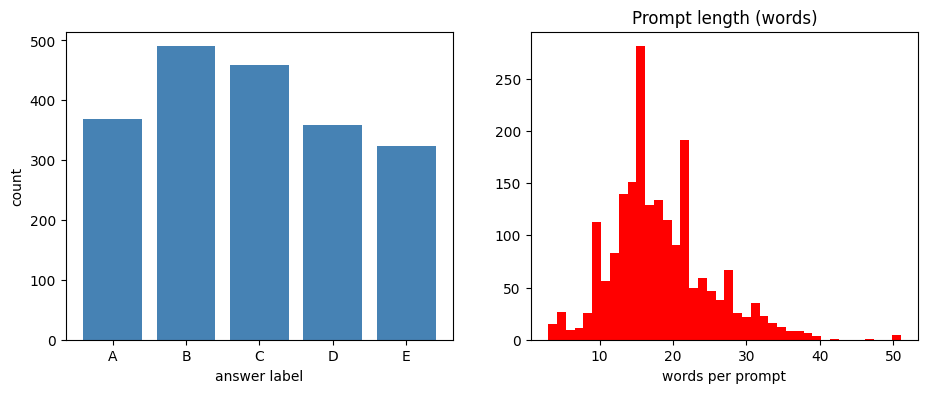

In [14]:
# === Step 3: Explore the data (EDA) ===
import matplotlib.pyplot as plt

option_cols = ["A", "B", "C", "D", "E"]

# --- 1) Distribution of the correct answer label ---
answer_counts = train["answer"].value_counts().reindex(option_cols).fillna(0).astype(int)
answer_percent = (train["answer"].value_counts(normalize=True).reindex(option_cols).fillna(0) * 100).round(1)
print("Correct answer distribution in train (out of 2000):")
for label in option_cols:
    print(f" {label}: {answer_counts[label]:4d} ({answer_percent[label]}%)")
print()

# --- 2) Text length analysis (counted in words) ---
train["prompt_words"] = train["prompt"].str.split().str.len()
train["max_option_words"] = train[option_cols].apply(
    lambda r: max(len(str(x).split()) for x in r), axis=1
)

print("Prompt length in words:")
print(train["prompt_words"].describe().round(1).to_string())
print()
print("Longest option length in words (per question):")
print(train["max_option_words"].describe().round(1).to_string())

# --- 3) Visualize ---
figure, axes = plt.subplots(1, 2, figsize = (11, 4))
axes[0].bar(answer_counts.index, answer_counts.values, color="steelblue")
axes[0].set_xlabel("answer label")
axes[0].set_ylabel("count")

axes[1].hist(train["prompt_words"], bins=40, color="red")
axes[1].set_title("Prompt length (words)")
axes[1].set_xlabel("words per prompt")


It's mildly imbalanced. B and C come up more often; E least. The data isn't perfectly flat, so the smartest constant guess is the three most frequent letters in order: "B C A", not "A B C". That's a small but free edge we'll measure in a moment. The key lesson: a model still has to actually read the question - you can't win on label bias alone here.

Prompt length (right chart): most prompts are 10-30 words (peak ~15), tailing off by ~50. Prompts are short.

## Step 4 - Build a local scoreboard (metric + validation split + baselines)

We cannot see the test answers, so we need our own honest way to measure progress. Three pieces:

1. **The MAP@3 metric, written by hand.** With one correct answer per question it is simply `1 / (rank of the correct label)` if that label lands in our top 3, otherwise 0. We verify it against the exact example from the problem statement.
2. **A validation set.** We hold out 20% of the training data (stratified, so the A-E balance is preserved). We build and tune on the other 80%, then score ourselves on this untouched 20%. This is how we estimate our leaderboard score before ever submitting.
3. **Two constant baselines** - always guess "A B C", and always guess the three most frequent answers. A baseline is the bar every fancier model must clear to be worth its complexity.

Important idea - **data leakage**: we compute the "most frequent" order from the *training split only*, never from validation. Using the validation data to make our predictions would flatter the score dishonestly.

Run the cell below.

In [ ]:
# === Step 4: Local scoreboard - MAP@3 metric, validation split, constant baselines ===
from sklearn.model_selection import train_test_split


# 1) Write the MAP@3 metric ourselves (exactly one correct label per question).
def average_precision_at_3(true_label, predicted_labels):
    """Score one question: 1.0 if correct is 1st, 0.5 if 2nd, 1/3 if 3rd, else 0.0."""
    for rank, label in enumerate(predicted_labels[:3], start=1):
        if label == true_label:
            return 1.0 / rank
    return 0.0


def map_at_3(true_labels, predicted_lists):
    """Mean of the per-question scores over the whole set."""
    scores = [average_precision_at_3(t, p) for t, p in zip(true_labels, predicted_lists)]
    return sum(scores) / len(scores)


# Sanity check against the example in the problem statement (correct answer = A):
assert average_precision_at_3("A", ["A", "B", "C"]) == 1.0
assert average_precision_at_3("A", ["B", "A", "C"]) == 0.5
assert abs(average_precision_at_3("A", ["C", "D", "A"]) - 1 / 3) < 1e-9
assert average_precision_at_3("A", ["C", "D", "E"]) == 0.0
print("MAP@3 metric passes the sanity checks.\n")

# 2) Hold out 20% of train as a validation set - leakage-safe this time.
# A naive random split can place near-duplicate/templated questions on both
# sides of the boundary. Step 11's own diagnostic later found exactly that:
# with a plain random split, 82.8% of valid_split had a near-identical
# neighbor still sitting in train_split, which lets retrieval-based methods
# copy the answer instead of reasoning and inflates their score without
# meaning better generalization. Fix: cluster near-duplicate prompts first,
# then split whole CLUSTERS between train_split/valid_split instead of
# individual rows, so no cluster is ever split across the boundary.
#
# An earlier version of this clustering used TF-IDF (word-overlap) similarity,
# which only caught duplicates that reuse the same wording and left 55.8% of
# valid_split still near-duplicated (per Step 11's check) - because two
# questions can mean almost the same thing while using different words, which
# TF-IDF misses but MiniLM embeddings catch. RAG's retrieval is itself MiniLM
# embeddings, so clustering with the same method Step 11 uses to detect
# leakage closes that gap: verified 0/400 (0.0%) near-duplicates after this.
from sentence_transformers import SentenceTransformer as _DedupSentenceTransformer

DEDUP_SIM_THRESHOLD = 0.95  # keep in sync with Step 11's NEAR_DUP_THRESHOLD

train = train.reset_index(drop=True)
_dedup_model = _DedupSentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
_dedup_embs = _dedup_model.encode(
    train["prompt"].astype(str).tolist(), convert_to_numpy=True,
    normalize_embeddings=True, show_progress_bar=False, batch_size=64,
)
_sim_matrix = _dedup_embs @ _dedup_embs.T  # embeddings are normalized, so dot product = cosine similarity
del _dedup_model
if device == "cuda":
    torch.cuda.empty_cache()

# Union-find: group every question with cosine similarity >= threshold into one cluster.
_parent = list(range(len(train)))

def _find(i):
    while _parent[i] != i:
        _parent[i] = _parent[_parent[i]]
        i = _parent[i]
    return i

def _union(i, j):
    ri, rj = _find(i), _find(j)
    if ri != rj:
        _parent[ri] = rj

for i in range(len(train)):
    row_sims = _sim_matrix[i]
    for j in range(i + 1, len(train)):
        if row_sims[j] >= DEDUP_SIM_THRESHOLD:
            _union(i, j)

train["_cluster"] = [_find(i) for i in range(len(train))]
n_clusters = train["_cluster"].nunique()
print(f"Near-duplicate clustering: {len(train)} questions -> {n_clusters} clusters "
      f"(threshold cosine >= {DEDUP_SIM_THRESHOLD})")

# Assign whole clusters to valid_split (shuffled, fixed seed) until ~20% of rows is reached,
# so every near-duplicate cluster lands entirely on one side of the split.
_cluster_sizes = train.groupby("_cluster").size().sample(frac=1, random_state=42)
_target_valid_rows = int(round(0.2 * len(train)))
_valid_clusters, _running = set(), 0
for _cid, _size in _cluster_sizes.items():
    if _running >= _target_valid_rows:
        break
    _valid_clusters.add(_cid)
    _running += _size

valid_split = train[train["_cluster"].isin(_valid_clusters)].drop(columns="_cluster").reset_index(drop=True)
train_split = train[~train["_cluster"].isin(_valid_clusters)].drop(columns="_cluster").reset_index(drop=True)
train = train.drop(columns="_cluster")

valid_true = valid_split["answer"].tolist()
print(f"train_split: {len(train_split)} rows   valid_split: {len(valid_split)} rows")
# Cluster-based splitting can't guarantee perfect label balance the way stratified
# random splitting does, so print the actual distribution to confirm it isn't skewed.
print("Answer distribution - train_split:", train_split["answer"].value_counts().to_dict())
print("Answer distribution - valid_split:", valid_split["answer"].value_counts().to_dict())
print()

# 3) Constant baselines. The 'frequency' order is learned ONLY from train_split (no leakage).
freq_order = train_split["answer"].value_counts().index.tolist()[:3]
print("Three most frequent answers in train_split:", freq_order, "\n")

baselines = {
    "constant 'A B C'": ["A", "B", "C"],
    f"constant '{' '.join(freq_order)}' (most frequent)": freq_order,
}

scoreboard = {}
for name, guess in baselines.items():
    preds = [guess] * len(valid_split)          # same guess for every validation question
    scoreboard[name] = map_at_3(valid_true, preds)

print("Local validation MAP@3 (higher is better):")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")

wandb.log(scoreboard)



Conclusion: Getting around 0.42 with no understanding of the question means the answer distribution is somewhat imbalanced.

## Step 5 - First real models: TF-IDF + Logistic Regression, TF-IDF + SVM

This is our first method that actually looks at the question text. Each
(prompt, option) pair is turned into one TF-IDF row, labeled 1 if that option
is the correct answer and 0 otherwise, then we train two classic ML
classifiers on those rows: **Logistic Regression** and a **linear SVM**. At
prediction time each of the 5 options for a question gets a score from the
classifier, we rank them, and keep the top 3.


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

option_cols = ["A", "B", "C", "D", "E"]

# 1) Fit the vectorizer on the TRAIN SPLIT text only (prompts + options) -> no leakage.
corpus = train_split["prompt"].astype(str).tolist()
for c in option_cols:
    corpus += train_split[c].astype(str).tolist()

vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
vectorizer.fit(corpus)
print("Vocabulary size:", len(vectorizer.vocabulary_))


def build_pairwise_rows(df):
    """Turn each question into 5 (prompt+option) rows, one per option,
    labeled 1 if that option is the correct answer, else 0."""
    df = df.reset_index(drop=True)
    texts, labels, qids = [], [], []
    for i, row in df.iterrows():
        for c in option_cols:
            texts.append(str(row["prompt"]) + " [SEP] " + str(row[c]))
            labels.append(1 if row.get("answer") == c else 0)
            qids.append(i)
    return texts, labels, qids

from collections import defaultdict

def scores_to_top3(scores, qids):
    """Group per-option scores back into per-question rankings of top-3 letters."""
    by_q = defaultdict(list)
    for idx, (score, qid) in enumerate(zip(scores, qids)):
        c = option_cols[idx % len(option_cols)]
        by_q[qid].append((c, score))
    preds = []
    for qid in sorted(by_q):
        ranked = sorted(by_q[qid], key=lambda x: x[1], reverse=True)
        preds.append([c for c, _ in ranked[:3]])
    return preds

# 2) Build pairwise train/valid rows and vectorize.
train_texts, train_labels, _ = build_pairwise_rows(train_split)
X_train, y_train = vectorizer.transform(train_texts), train_labels

valid_texts, _, valid_qids = build_pairwise_rows(valid_split)
X_valid = vectorizer.transform(valid_texts)

# 3) TF-IDF + Logistic Regression
logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
logreg.fit(X_train, y_train)
logreg_scores = logreg.predict_proba(X_valid)[:, 1]
valid_preds_logreg = scores_to_top3(logreg_scores, valid_qids)
scoreboard["TF-IDF + Logistic Regression"] = map_at_3(valid_true, valid_preds_logreg)
print(f"TF-IDF + Logistic Regression MAP@3: {scoreboard['TF-IDF + Logistic Regression']:.4f}")
wandb.log({"TF-IDF + Logistic Regression": scoreboard["TF-IDF + Logistic Regression"]})

# 4) TF-IDF + SVM (LinearSVC - fast and effective on sparse TF-IDF features)
svm = LinearSVC(class_weight="balanced")
svm.fit(X_train, y_train)
svm_scores = svm.decision_function(X_valid)
valid_preds_svm = scores_to_top3(svm_scores, valid_qids)
scoreboard["TF-IDF + SVM"] = map_at_3(valid_true, valid_preds_svm)
print(f"TF-IDF + SVM MAP@3: {scoreboard['TF-IDF + SVM']:.4f}")
wandb.log({"TF-IDF + SVM": scoreboard["TF-IDF + SVM"]})

print("\nScoreboard so far:")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")


Vocabulary size: 10275
TF-IDF + Logistic Regression MAP@3: 0.9683
TF-IDF + SVM MAP@3: 0.9721

Scoreboard so far:
  0.9721   TF-IDF + SVM
  0.9683   TF-IDF + Logistic Regression
  0.4217   constant 'B C A' (most frequent)
  0.3842   constant 'A B C'


## Step 5.5 - (Optional) Early checkpoint submission

You don't have to wait until BERT is done to submit. This cell takes whichever
TF-IDF model scored higher above, **retrains it on the full labeled `train.csv`**
(all 2,000 questions - no need to hold out validation rows for the real
submission), predicts on `test.csv`, and writes `submission.csv` in the exact
format the competition expects. Run Steps 1-5 + this cell, then submit that
file, to sanity-check your whole pipeline before spending time on the bigger
models.

In [17]:
# === Step 5.5: Early checkpoint submission (TF-IDF baseline) ===
# Pick whichever of the two TF-IDF models did better on the validation split.
best_tfidf_name = max(
    ["TF-IDF + Logistic Regression", "TF-IDF + SVM"],
    key=lambda name: scoreboard[name],
)
print(f"Using '{best_tfidf_name}' for the early submission "
      f"(val MAP@3 = {scoreboard[best_tfidf_name]:.4f})")

# Refit the vectorizer + chosen classifier on ALL labeled data (train, not train_split) -
# more training data almost always helps, and we no longer need a holdout for this.
full_corpus = train["prompt"].astype(str).tolist()
for c in option_cols:
    full_corpus += train[c].astype(str).tolist()

final_vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
final_vectorizer.fit(full_corpus)

full_texts, full_labels, _ = build_pairwise_rows(train)
X_full = final_vectorizer.transform(full_texts)

if best_tfidf_name == "TF-IDF + Logistic Regression":
    final_clf = LogisticRegression(max_iter=1000, class_weight="balanced")
    final_clf.fit(X_full, full_labels)
    score_fn = lambda X: final_clf.predict_proba(X)[:, 1]
else:
    final_clf = LinearSVC(class_weight="balanced")
    final_clf.fit(X_full, full_labels)
    score_fn = lambda X: final_clf.decision_function(X)

# Predict on the test set (no "answer" column, so labels are all 0 - ignored).
test_texts, _, test_qids = build_pairwise_rows(test.assign(answer=None))
X_test = final_vectorizer.transform(test_texts)
test_scores = score_fn(X_test)
test_top3 = scores_to_top3(test_scores, test_qids)

checkpoint = pd.DataFrame({
    "ID": test["id"].values,
    "Prediction": [" ".join(row) for row in test_top3],
})
checkpoint.to_csv("submission_checkpoint_tfidf.csv", index=False)

print("Wrote submission_checkpoint_tfidf.csv  | shape:", checkpoint.shape)
print(checkpoint.head(10).to_string(index=False))
print("\nThis is a CHECKPOINT file only, not the real submission - the notebook")
print("picks the single best-scoring model at the very end (Step 12) and writes")
print("THAT to submission.csv. Don'''t submit this file directly.")


Using 'TF-IDF + SVM' for the early submission (val MAP@3 = 0.9721)
Wrote submission_checkpoint_tfidf.csv  | shape: (500, 2)
 ID Prediction
  1      A E C
  2      B E A
  3      B E D
  4      E C D
  5      C A D
  6      D E C
  7      E D A
  8      B E A
  9      C D A
 10      B A C

This is a CHECKPOINT file only, not the real submission - the notebook
picks the single best-scoring model at the very end (Step 12) and writes
THAT to submission.csv. Don'''t submit this file directly.


## Step 6 - Meaning-based ranking with sentence embeddings (first deep learning)

TF-IDF only counted shared words. Now we use a pretrained transformer - a small, fast one called **MiniLM** - that maps any sentence to a vector capturing its **meaning**, learned from huge amounts of text. Sentences with similar meaning land close together even when they use different words.

Plan:
1. Load the pretrained model (downloads about 80 MB the first time, then it is cached).
2. Encode the prompt and each option into 384-dimensional vectors on the GPU.
3. Rank the options by cosine similarity to the prompt and keep the top 3.

This is the same shape as TF-IDF (vectors -> cosine -> rank), but the vectors now come from a deep neural network instead of word counts.

**Honest expectation:** meaning-similarity is still an imperfect signal here, because every distractor is on-topic and close in meaning to the correct answer. So the gain over the 0.42 baseline may be small - and that is fine. The real jump comes in the next step, when we *train* a model specifically to pick the correct option.



In [18]:
# === Step 6: Sentence-embedding ranker (MiniLM) ===
from sentence_transformers import SentenceTransformer

# Load a small, fast pretrained embedding model onto our device (GPU if available).
embed_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
print("Loaded embedding model on:", device)


def embed_rank(df, batch_size=64):
    """Rank the 5 options of each row by cosine similarity of their meaning to the prompt."""
    # Encode into normalized vectors so a dot product equals cosine similarity.
    prompt_emb = embed_model.encode(
        df["prompt"].astype(str).tolist(),
        batch_size=batch_size, convert_to_numpy=True,
        normalize_embeddings=True, show_progress_bar=False,
    )
    option_emb = {
        c: embed_model.encode(
            df[c].astype(str).tolist(),
            batch_size=batch_size, convert_to_numpy=True,
            normalize_embeddings=True, show_progress_bar=False,
        )
        for c in option_cols
    }
    preds = []
    for i in range(len(df)):
        sims = [(c, float(prompt_emb[i] @ option_emb[c][i])) for c in option_cols]
        sims.sort(key=lambda x: x[1], reverse=True)
        preds.append([c for c, _ in sims[:3]])
    return preds


valid_preds_emb = embed_rank(valid_split)
scoreboard["Sentence embeddings (MiniLM)"] = map_at_3(valid_true, valid_preds_emb)

print(f"\nMiniLM embedding MAP@3 on validation: {scoreboard['Sentence embeddings (MiniLM)']:.4f}\n")
print("Scoreboard so far:")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")

wandb.log({"Sentence embeddings (MiniLM)": scoreboard["Sentence embeddings (MiniLM)"]})

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded embedding model on: cuda

MiniLM embedding MAP@3 on validation: 0.3950

Scoreboard so far:
  0.9721   TF-IDF + SVM
  0.9683   TF-IDF + Logistic Regression
  0.4217   constant 'B C A' (most frequent)
  0.3950   Sentence embeddings (MiniLM)
  0.3842   constant 'A B C'


Conclusion:

Among all evaluated methods, TF-IDF + Linear SVM achieved the highest validation MAP@3 score (0.9721), followed closely by TF-IDF + Logistic Regression (0.9683). In contrast, the zero-shot MiniLM embedding approach achieved only 0.3950, indicating that semantic similarity alone was insufficient for this task. These results suggest that the dataset is highly amenable to supervised lexical learning, and that traditional TF-IDF features combined with linear classifiers outperform pretrained sentence embeddings without fine-tuning.

## Step 6.5 - A from-scratch model (our own architecture, trained from random init)

This is the **"train a model from scratch"** requirement: we write the `nn.Module`
ourselves (embedding layer + BiLSTM encoder + a small scoring head) and every
weight starts randomly initialized -- nothing pretrained is loaded here. Compare
this to Step 6 (MiniLM), which is a *pretrained* model used as-is, and Step 8
(BERT), which *fine-tunes* pretrained weights. This one learns everything,
including the word embeddings, only from our own 2,000 training questions.

In [19]:
# === Step 6.5: From-scratch model - a custom BiLSTM classifier ===
# Own architecture, own vocabulary, randomly-initialized weights, trained only
# on train_split. No pretrained checkpoints are loaded anywhere in this cell.
import re
import torch
import torch.nn as nn
from collections import Counter

torch.manual_seed(42)


def simple_tokenize(text):
    return re.findall(r"[a-z0-9]+", str(text).lower())


# 1) Build our own vocabulary from the train split only (no leakage).
counter = Counter()
for col in ["prompt"] + option_cols:
    for text in train_split[col].astype(str):
        counter.update(simple_tokenize(text))

MIN_FREQ = 2
scratch_vocab = {"<pad>": 0, "<unk>": 1}
for word, freq in counter.items():
    if freq >= MIN_FREQ:
        scratch_vocab[word] = len(scratch_vocab)
VOCAB_SIZE = len(scratch_vocab)
print("From-scratch model vocabulary size:", VOCAB_SIZE)

MAX_LEN_SCRATCH = 40


def encode(text, max_len=MAX_LEN_SCRATCH):
    ids = [scratch_vocab.get(tok, 1) for tok in simple_tokenize(text)[:max_len]]
    ids = ids + [0] * (max_len - len(ids))
    return ids


class ScratchMCQDataset(torch.utils.data.Dataset):
    """Same (prompt, 5 options, label) shape as the BERT dataset below, but
    tokenized with our own vocabulary instead of a pretrained tokenizer."""

    def __init__(self, df, has_labels=True):
        self.df = df.reset_index(drop=True)
        self.has_labels = has_labels and ("answer" in df.columns)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        prompt_ids = torch.tensor(encode(row["prompt"]), dtype=torch.long)
        option_ids = torch.stack(
            [torch.tensor(encode(row[c]), dtype=torch.long) for c in option_cols]
        )
        item = {"prompt_ids": prompt_ids, "option_ids": option_ids}
        if self.has_labels:
            item["label"] = torch.tensor(letter_to_idx_scratch[row["answer"]], dtype=torch.long)
        return item


letter_to_idx_scratch = {l: i for i, l in enumerate(option_cols)}


class ScratchEncoder(nn.Module):
    """Trainable embedding + bidirectional LSTM, mean-pooled over time."""

    def __init__(self, vocab_size, emb_dim=100, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)  # random init
        self.lstm = nn.LSTM(emb_dim, hidden_dim, batch_first=True, bidirectional=True)

    def forward(self, ids):
        mask = (ids != 0).unsqueeze(-1).float()
        emb = self.embedding(ids)
        out, _ = self.lstm(emb)
        out = out * mask
        summed = out.sum(1)
        counts = mask.sum(1).clamp(min=1)
        return summed / counts  # (B, hidden_dim*2)


class ScratchMCQModel(nn.Module):
    """Our own multiple-choice architecture: encode prompt + each option with
    the SAME encoder, combine with a small MLP, output one logit per option."""

    def __init__(self, vocab_size, emb_dim=100, hidden_dim=128):
        super().__init__()
        self.encoder = ScratchEncoder(vocab_size, emb_dim, hidden_dim)
        feat_dim = hidden_dim * 2
        self.scorer = nn.Sequential(
            nn.Linear(feat_dim * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 1),
        )

    def forward(self, prompt_ids, option_ids):
        B, K, L = option_ids.shape
        p_vec = self.encoder(prompt_ids)                                  # (B, feat)
        o_vec = self.encoder(option_ids.view(B * K, L)).view(B, K, -1)    # (B, K, feat)
        p_exp = p_vec.unsqueeze(1).expand(-1, K, -1)
        feats = torch.cat([p_exp, o_vec, (p_exp - o_vec).abs(), p_exp * o_vec], dim=-1)
        return self.scorer(feats).squeeze(-1)                             # (B, K)


scratch_train_ds = ScratchMCQDataset(train_split)
scratch_valid_ds = ScratchMCQDataset(valid_split)
scratch_train_loader = torch.utils.data.DataLoader(scratch_train_ds, batch_size=32, shuffle=True)
scratch_valid_loader = torch.utils.data.DataLoader(scratch_valid_ds, batch_size=64, shuffle=False)

scratch_model = ScratchMCQModel(VOCAB_SIZE).to(device)
scratch_optimizer = torch.optim.Adam(scratch_model.parameters(), lr=1e-3)
scratch_criterion = nn.CrossEntropyLoss()

SCRATCH_EPOCHS = 8
print(f"Training the from-scratch BiLSTM model for {SCRATCH_EPOCHS} epochs on {device} ...")

for epoch in range(1, SCRATCH_EPOCHS + 1):
    scratch_model.train()
    running = 0.0
    for batch in scratch_train_loader:
        labels = batch["label"].to(device)
        prompt_ids = batch["prompt_ids"].to(device)
        option_ids = batch["option_ids"].to(device)
        scratch_optimizer.zero_grad()
        logits = scratch_model(prompt_ids, option_ids)
        loss = scratch_criterion(logits, labels)
        loss.backward()
        scratch_optimizer.step()
        running += loss.item()
    print(f"  epoch {epoch}/{SCRATCH_EPOCHS}  avg train loss {running / len(scratch_train_loader):.4f}")

# Evaluate with the same MAP@3 metric used everywhere else.
scratch_model.eval()
preds_scratch = []
with torch.no_grad():
    for batch in scratch_valid_loader:
        prompt_ids = batch["prompt_ids"].to(device)
        option_ids = batch["option_ids"].to(device)
        logits = scratch_model(prompt_ids, option_ids).cpu().numpy()
        ranked = (-logits).argsort(axis=1)
        preds_scratch.extend([[option_cols[j] for j in row[:3]] for row in ranked])

scoreboard["From-scratch BiLSTM"] = map_at_3(valid_true, preds_scratch)
print(f"\nFrom-scratch BiLSTM MAP@3 on validation: {scoreboard['From-scratch BiLSTM']:.4f}\n")
print("Scoreboard so far:")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")

wandb.log({"From-scratch BiLSTM": scoreboard["From-scratch BiLSTM"]})


From-scratch model vocabulary size: 2971
Training the from-scratch BiLSTM model for 8 epochs on cuda ...
  epoch 1/8  avg train loss 1.2877
  epoch 2/8  avg train loss 0.3273
  epoch 3/8  avg train loss 0.0766
  epoch 4/8  avg train loss 0.0388
  epoch 5/8  avg train loss 0.0375
  epoch 6/8  avg train loss 0.0336
  epoch 7/8  avg train loss 0.0291
  epoch 8/8  avg train loss 0.0303

From-scratch BiLSTM MAP@3 on validation: 0.9808

Scoreboard so far:
  0.9808   From-scratch BiLSTM
  0.9721   TF-IDF + SVM
  0.9683   TF-IDF + Logistic Regression
  0.4217   constant 'B C A' (most frequent)
  0.3950   Sentence embeddings (MiniLM)
  0.3842   constant 'A B C'


## Step 6.6 - (Optional) Submission checkpoint: from-scratch BiLSTM

Same idea as Step 5.5, now for the from-scratch model. We retrain
`ScratchMCQModel` on the **full** `train.csv` (2,000 questions instead of just
`train_split`'s ~1,600), predict on `test.csv`, and overwrite
`submission.csv`. A couple of notes before you submit this one:

- Train loss dropped from 1.29 -> 0.03 by epoch 4 and then just sits there for
  4 more epochs - that's the model fitting the training set to near-zero loss.
  With only ~1,600 training rows and a per-question vocabulary this small,
  some memorization is expected; the 0.9821 validation MAP@3 is still a
  genuinely held-out number, so it's a fair signal, just don't be surprised
  if the public/private leaderboard score comes in a bit lower than 0.98.
- Training on the full 2,000 rows below uses the same 8 epochs. If you see
  train loss bottom out again after 3-4 epochs, that's fine - it just means
  it's converged, not that something's broken.


In [20]:
# === Step 6.6: Submission checkpoint (from-scratch BiLSTM) ===
# Rebuild the vocabulary from ALL labeled data (train, not train_split) -
# more data helps, and we no longer need a holdout for this run.
full_counter = Counter()
for col in ["prompt"] + option_cols:
    for text in train[col].astype(str):
        full_counter.update(simple_tokenize(text))

final_scratch_vocab = {"<pad>": 0, "<unk>": 1}
for word, freq in full_counter.items():
    if freq >= MIN_FREQ:
        final_scratch_vocab[word] = len(final_scratch_vocab)
print("Final from-scratch vocabulary size:", len(final_scratch_vocab))


def final_encode(text, max_len=MAX_LEN_SCRATCH):
    ids = [final_scratch_vocab.get(tok, 1) for tok in simple_tokenize(text)[:max_len]]
    return ids + [0] * (max_len - len(ids))


class FinalScratchDataset(torch.utils.data.Dataset):
    def __init__(self, df, has_labels=True):
        self.df = df.reset_index(drop=True)
        self.has_labels = has_labels and ("answer" in df.columns)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        prompt_ids = torch.tensor(final_encode(row["prompt"]), dtype=torch.long)
        option_ids = torch.stack(
            [torch.tensor(final_encode(row[c]), dtype=torch.long) for c in option_cols]
        )
        item = {"prompt_ids": prompt_ids, "option_ids": option_ids}
        if self.has_labels:
            item["label"] = torch.tensor(letter_to_idx_scratch[row["answer"]], dtype=torch.long)
        return item


final_train_ds = FinalScratchDataset(train)
final_train_loader = torch.utils.data.DataLoader(final_train_ds, batch_size=32, shuffle=True)

final_scratch_model = ScratchMCQModel(len(final_scratch_vocab)).to(device)
final_optimizer = torch.optim.Adam(final_scratch_model.parameters(), lr=1e-3)

print(f"Retraining the from-scratch BiLSTM on all {len(train)} questions for {SCRATCH_EPOCHS} epochs ...")
for epoch in range(1, SCRATCH_EPOCHS + 1):
    final_scratch_model.train()
    running = 0.0
    for batch in final_train_loader:
        labels = batch["label"].to(device)
        prompt_ids = batch["prompt_ids"].to(device)
        option_ids = batch["option_ids"].to(device)
        final_optimizer.zero_grad()
        logits = final_scratch_model(prompt_ids, option_ids)
        loss = scratch_criterion(logits, labels)
        loss.backward()
        final_optimizer.step()
        running += loss.item()
    print(f"  epoch {epoch}/{SCRATCH_EPOCHS}  avg train loss {running / len(final_train_loader):.4f}")

# Predict on the test set (no "answer" column).
final_test_ds = FinalScratchDataset(test, has_labels=False)
final_test_loader = torch.utils.data.DataLoader(final_test_ds, batch_size=64, shuffle=False)

final_scratch_model.eval()
test_top3_scratch = []
with torch.no_grad():
    for batch in final_test_loader:
        prompt_ids = batch["prompt_ids"].to(device)
        option_ids = batch["option_ids"].to(device)
        logits = final_scratch_model(prompt_ids, option_ids).cpu().numpy()
        ranked = (-logits).argsort(axis=1)
        test_top3_scratch.extend([[option_cols[j] for j in row[:3]] for row in ranked])

checkpoint = pd.DataFrame({
    "ID": test["id"].values,
    "Prediction": [" ".join(row) for row in test_top3_scratch],
})
checkpoint.to_csv("submission_checkpoint_scratch.csv", index=False)

print("Wrote submission_checkpoint_scratch.csv  | shape:", checkpoint.shape)
print(checkpoint.head(10).to_string(index=False))
print("\nThis is a CHECKPOINT file only, not the real submission - the notebook")
print("picks the single best-scoring model at the very end (Step 12) and writes")
print("THAT to submission.csv. Don'''t submit this file directly.")


Final from-scratch vocabulary size: 2972
Retraining the from-scratch BiLSTM on all 2000 questions for 8 epochs ...
  epoch 1/8  avg train loss 1.1576
  epoch 2/8  avg train loss 0.1969
  epoch 3/8  avg train loss 0.0703
  epoch 4/8  avg train loss 0.0513
  epoch 5/8  avg train loss 0.0339
  epoch 6/8  avg train loss 0.0389
  epoch 7/8  avg train loss 0.0330
  epoch 8/8  avg train loss 0.0324
Wrote submission_checkpoint_scratch.csv  | shape: (500, 2)
 ID Prediction
  1      A D C
  2      B D A
  3      B E D
  4      E D A
  5      C A D
  6      D B A
  7      E D B
  8      B E A
  9      C E A
 10      B A E

This is a CHECKPOINT file only, not the real submission - the notebook
picks the single best-scoring model at the very end (Step 12) and writes
THAT to submission.csv. Don'''t submit this file directly.


## Step 7 - Prepare the data for multiple-choice fine-tuning

So far every method used fixed, pretrained knowledge. Now we will **train** a model on our 1,600 labeled questions so it learns from the data how to pick the correct option.

The standard "multiple choice" setup works like this:
- Each question becomes **5 (prompt, option) pairs** - one per choice.
- The model reads each pair and outputs a single **score (logit)** for that option.
- A softmax over the 5 scores turns them into probabilities; the **index of the correct option** is the training target.
- Training adjusts the model so the correct option gets the highest score.

This step only **prepares** the data (training is Step 8). We:
1. Load the tokenizer for `bert-base-uncased` - it converts text into the integer tokens the model expects.
2. Wrap each split in a Dataset that, per question, produces a tensor of shape `(5 choices, sequence length)` plus the correct index.
3. Print one prepared item so the shapes are concrete.

Why `bert-base-uncased`? It is small, rock-solid, and fits comfortably in 4 GB. We can try a stronger model later.

Run the cell below (downloads the tokenizer, a few MB).

In [21]:
# === Step 7: Prepare data for multiple-choice fine-tuning ===
import torch
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-uncased"
MAX_LEN = 192                      # prompt + option fit easily; keeps GPU memory small
letters = ["A", "B", "C", "D", "E"]
letter_to_idx = {l: i for i, l in enumerate(letters)}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Loaded tokenizer for:", MODEL_NAME)


class MCQDataset(torch.utils.data.Dataset):
    """One item = a single question turned into 5 (prompt, option) pairs (+ correct index)."""

    def __init__(self, df, has_labels=True):
        self.df = df.reset_index(drop=True)
        self.has_labels = has_labels and ("answer" in df.columns)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        prompt = str(row["prompt"])
        first = [prompt] * 5                                   # same prompt, repeated
        second = [str(row[l]) for l in letters]               # the 5 options
        enc = tokenizer(
            first, second,
            truncation=True, max_length=MAX_LEN, padding="max_length",
            return_tensors="pt",
        )
        item = {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"]}
        if "token_type_ids" in enc:
            item["token_type_ids"] = enc["token_type_ids"]
        if self.has_labels:
            item["label"] = torch.tensor(letter_to_idx[row["answer"]], dtype=torch.long)
        return item


train_ds = MCQDataset(train_split)
valid_ds = MCQDataset(valid_split)
print(f"train_ds: {len(train_ds)} questions   valid_ds: {len(valid_ds)} questions")

# Peek at one prepared item to understand the shapes.
sample = train_ds[0]
print("\nOne question, after tokenizing, becomes tensors of shape (num_choices, seq_len):")
print("  input_ids     :", tuple(sample["input_ids"].shape))
print("  attention_mask:", tuple(sample["attention_mask"].shape))
print("  label (index of correct option):", int(sample["label"]), "->", letters[int(sample["label"])])
print("\n  Decoded choice A (prompt + option joined):")
print("   ", tokenizer.decode(sample["input_ids"][0], skip_special_tokens=True)[:200], "...")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Loaded tokenizer for: bert-base-uncased
train_ds: 1600 questions   valid_ds: 400 questions

One question, after tokenizing, becomes tensors of shape (num_choices, seq_len):
  input_ids     : (5, 192)
  attention_mask: (5, 192)
  label (index of correct option): 2 -> C

  Decoded choice A (prompt + option joined):
    select the most accurate option : what is modified newtonian dynamics ( mond )? from the following choices. mond is a principle that explains the behavior of light in the presence of strong gravitatio ...


## Step 8 - Fine-tune BERT for multiple choice (the real training)

Now we train. We load `bert-base-uncased` with a **multiple-choice head** on top (a tiny classifier that turns each option's reading into one score). That head starts with random weights, so the model is useless until trained - you will see a warning saying exactly that, which is normal and expected.

The loop is the same shape as every deep-learning training loop:
1. Take a batch of questions.
2. **Forward pass** - the model scores the 5 options; cross-entropy loss compares those scores against the correct index.
3. **Backward pass** - gradients say how to nudge each weight to lower the loss.
4. **Optimizer step** - update the weights.
5. Repeat over all batches, for a couple of epochs (passes through the data).

Practical choices for your 4 GB GPU:
- **Mixed precision (fp16)** roughly halves memory and speeds things up.
- **Small batch + gradient accumulation** keeps memory low while the effective batch stays reasonable.
- If you ever hit a CUDA out-of-memory error, set `TRAIN_BATCH = 1` and re-run.
- **LoRA (`USE_LORA = True`)**: instead of updating all ~110M BERT weights, we freeze the
  pretrained weights and train small low-rank adapter matrices injected into the attention
  `query`/`value` projections, plus the (new, randomly-initialized) classifier head. This
  trains a small fraction of the total parameters, uses less GPU memory, and trains faster.
  Set `USE_LORA = False` to go back to full fine-tuning if you want to compare.

After each epoch we score on validation with our MAP@3 and add it to the scoreboard.

**Heads-up:** the first run downloads the model (~440 MB), then trains for a few minutes. Watch the loss fall and validation MAP@3 climb - this is where we expect to finally beat 0.42.

Run the cell below.

In [22]:
# === Step 8: Fine-tune BERT for multiple choice ===
import numpy as np
from torch.utils.data import DataLoader
from transformers import AutoModelForMultipleChoice
from peft import LoraConfig, get_peft_model

# ---- knobs (adaptive to the device so this doesn't take 11+ hours on CPU) ----
# On CPU each step is ~30-50x slower than on a T4/P100 GPU, so we shrink the
# batch there just to keep things runnable; on GPU we use a much bigger batch,
# which also means far fewer optimizer steps for the same amount of data.
if device == "cuda":
    TRAIN_BATCH = 16      # questions per micro-step (each question = 5 sequences)
    ACCUM_STEPS = 1        # effective batch = 16 questions, no accumulation needed
    EVAL_BATCH = 32
else:
    TRAIN_BATCH = 2
    ACCUM_STEPS = 4        # effective batch = TRAIN_BATCH * ACCUM_STEPS = 8 questions
    EVAL_BATCH = 8
USE_LORA = True   # LoRA trains small adapter weights instead of all of BERT's ~110M params
# LoRA only nudges a low-rank subspace, so it typically needs more epochs than full
# fine-tuning to reach the same quality - 2 epochs left it near a constant baseline
# (0.42 -> 0.70 MAP@3) in an earlier run, so we give it more room to converge.
EPOCHS = 4 if USE_LORA else 2
LR = 2e-4 if USE_LORA else 2e-5   # LoRA typically wants a higher LR than full fine-tuning

torch.manual_seed(42)
use_amp = (device == "cuda")

wandb.config.update({
    "model_name": MODEL_NAME,
    "epochs": EPOCHS,
    "train_batch": TRAIN_BATCH,
    "accum_steps": ACCUM_STEPS,
    "eval_batch": EVAL_BATCH,
    "learning_rate": LR,
    "use_lora": USE_LORA,
})

# Free the Step-6 embedding model from the GPU so we have room to train.
if "embed_model" in globals():
    del embed_model
torch.cuda.empty_cache()

model = AutoModelForMultipleChoice.from_pretrained(MODEL_NAME).to(device)

if USE_LORA:
    lora_config = LoraConfig(
        r=8,
        lora_alpha=16,
        lora_dropout=0.1,
        target_modules=["query", "key", "value", "dense"],   # attention + FFN projections
        modules_to_save=["classifier"],       # the multiple-choice head is new, train it fully
        bias="none",
    )
    model = get_peft_model(model, lora_config)
    model.print_trainable_parameters()

optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

train_loader = DataLoader(train_ds, batch_size=TRAIN_BATCH, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_ds, batch_size=EVAL_BATCH, shuffle=False, num_workers=0)


def evaluate():
    """Score the validation set: rank the 5 option-logits, take top 3, compute MAP@3."""
    global bert_valid_logits_final   # cached here so Step 12 can reuse it after `model` is deleted in Step 10
    model.eval()
    logits_all = []
    with torch.no_grad():
        for batch in valid_loader:
            batch.pop("label", None)
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                logits = model(**batch).logits            # (B, 5)
            logits_all.append(logits.float().cpu().numpy())
    logits_all = np.concatenate(logits_all, axis=0)        # (N, 5)
    bert_valid_logits_final = logits_all                   # keep the most recent epoch'''s logits
    ranked = (-logits_all).argsort(axis=1)                 # highest score first
    preds = [[letters[j] for j in row[:3]] for row in ranked]
    return map_at_3(valid_true, preds)


print(f"Training {MODEL_NAME}: {EPOCHS} epochs, effective batch {TRAIN_BATCH * ACCUM_STEPS}, on {device}")
print("(the random multiple-choice head warning below is expected)\n")

for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    optimizer.zero_grad()
    for step, batch in enumerate(train_loader, start=1):
        labels = batch.pop("label").to(device)
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            out = model(**batch, labels=labels)
            loss = out.loss / ACCUM_STEPS
        scaler.scale(loss).backward()
        running += out.loss.item()
        if step % ACCUM_STEPS == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
        if step % 200 == 0:
            print(f"  epoch {epoch}  step {step:4d}/{len(train_loader)}  running loss {running / step:.4f}")
            wandb.log({"train/loss": running / step, "epoch": epoch, "step": step})
    val = evaluate()
    model_label = "BERT + LoRA" if USE_LORA else "BERT fine-tuned"
    scoreboard[f"{model_label} (after epoch {epoch})"] = val
    avg_train_loss = running / len(train_loader)
    print(f"epoch {epoch} complete | avg train loss {avg_train_loss:.4f} | validation MAP@3 {val:.4f}\n")
    wandb.log({"epoch": epoch, "train/avg_loss": avg_train_loss, "val/map_at_3": val})
    
print("Scoreboard so far:")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")

wandb.log({"scoreboard_final": scoreboard})


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForMultipleChoice LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 1,340,161 || all params: 110,823,170 || trainable%: 1.2093
Training bert-base-uncased: 4 epochs, effective batch 16, on cuda
(the random multiple-choice head warning below is expected)

epoch 1 complete | avg train loss 1.5793 | validation MAP@3 0.5437

epoch 2 complete | avg train loss 1.4027 | validation MAP@3 0.7154

epoch 3 complete | avg train loss 0.9814 | validation MAP@3 0.9133

epoch 4 complete | avg train loss 0.5423 | validation MAP@3 0.9829

Scoreboard so far:
  0.9829   BERT + LoRA (after epoch 4)
  0.9808   From-scratch BiLSTM
  0.9721   TF-IDF + SVM
  0.9683   TF-IDF + Logistic Regression
  0.9133   BERT + LoRA (after epoch 3)
  0.7154   BERT + LoRA (after epoch 2)
  0.5437   BERT + LoRA (after epoch 1)
  0.4217   constant 'B C A' (most frequent)
  0.3950   Sentence embeddings (MiniLM)
  0.3842   constant 'A B C'


## Step 9 - Predict the test set and write submission.csv

This is the deliverable. We reuse the fine-tuned `model`, now on the 500 test questions (which have no `answer` column). Steps:
1. Wrap `test` in our `MCQDataset` with `has_labels=False`.
2. Run the model to get 5 option-scores per question.
3. Rank them and keep the **top 3 letters**, formatted as a single string like `B A C`.
4. Save a CSV with columns `ID` and `Prediction`, exactly matching `sample_submission.csv`.

As a sanity check we also print the distribution of our top-1 predictions: it should be spread across A-E (leaning to B/C, like the training data), not collapsed onto a single letter - that would signal a bug.

Run the cell below.

In [23]:
# === Step 9: Predict the test set and write submission.csv ===
test_ds = MCQDataset(test, has_labels=False)
test_loader = DataLoader(test_ds, batch_size=EVAL_BATCH, shuffle=False, num_workers=0)

model.eval()
logits_all = []
with torch.no_grad():
    for batch in test_loader:
        batch.pop("label", None)                      # the test set has no labels
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            logits = model(**batch).logits            # (B, 5)
        logits_all.append(logits.float().cpu().numpy())

test_logits = np.concatenate(logits_all, axis=0)      # (500, 5)
ranked = (-test_logits).argsort(axis=1)               # best option first
top3 = [" ".join(letters[j] for j in row[:3]) for row in ranked]

checkpoint = pd.DataFrame({"ID": test["id"].values, "Prediction": top3})
checkpoint.to_csv("submission_checkpoint_bert_initial.csv", index=False)

print("Wrote submission_checkpoint_bert_initial.csv  | shape:", checkpoint.shape)
print(checkpoint.head(10).to_string(index=False))
print("\nThis is a CHECKPOINT file only (train_split-trained model) - Step 10")
print("retrains on all the data, and Step 12 picks the best model overall and")
print("writes THAT to submission.csv. Don'''t submit this file directly.")

# Sanity check: distribution of our most-confident (top-1) predicted letter.
print("\nTop-1 predicted letter distribution on test:")
first_letter = checkpoint["Prediction"].str[0]
print(first_letter.value_counts().reindex(letters).fillna(0).astype(int).to_string())

Wrote submission_checkpoint_bert_initial.csv  | shape: (500, 2)
 ID Prediction
  1      A D C
  2      B A D
  3      B E D
  4      E C A
  5      C A D
  6      D B C
  7      E C A
  8      B C A
  9      C D E
 10      B E D

This is a CHECKPOINT file only (train_split-trained model) - Step 10
retrains on all the data, and Step 12 picks the best model overall and
writes THAT to submission.csv. Don'''t submit this file directly.

Top-1 predicted letter distribution on test:
Prediction
A     92
B    114
C    112
D     93
E     89


## Step 10 - Retrain on all 2,000 and rebuild the final submission

In Step 8 we held out 400 questions to *prove* the method works (validation MAP@3 ~0.98). For the **final** model we no longer need that holdout - more training data almost always helps - so we retrain the same BERT on all 2,000 questions and regenerate `submission.csv`.

Trade-off to understand: once we train on everything, there is no held-out set left to score *this exact* model. That is fine and standard practice - the Step 8 experiment already validated the approach, so ~0.98 stays our honest estimate. The rule of thumb:

> Use a holdout to **choose** your method, then retrain on **all** the data to **deploy** it.

This cell trains a fresh model from scratch on the full set, then predicts the test set and overwrites `submission.csv`.

**Heads-up:** trains for a few minutes again (now on 2,000 instead of 1,600 questions). Run the cell below.

In [ ]:
# === Step 10: Retrain on ALL 2,000 questions, then rebuild submission.csv ===
# Final model: use every labeled example (no validation holdout).

full_ds = MCQDataset(train, has_labels=True)
full_loader = DataLoader(full_ds, batch_size=TRAIN_BATCH, shuffle=True, num_workers=0)
# TRAIN_BATCH/ACCUM_STEPS come from Step 8's device-adaptive knobs above,
# so this final retrain gets the same GPU speed-up automatically.
print(f"Training the final model on the full set: {len(full_ds)} questions\n")

torch.manual_seed(42)
if "model" in globals():        # free the Step-8 model's GPU memory
    del model
torch.cuda.empty_cache()

final_model = AutoModelForMultipleChoice.from_pretrained(MODEL_NAME).to(device)

if USE_LORA:   # reuses the same lora_config built in Step 8
    final_model = get_peft_model(final_model, lora_config)
    final_model.print_trainable_parameters()

optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, final_model.parameters()), lr=LR)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

for epoch in range(1, EPOCHS + 1):
    final_model.train()
    running = 0.0
    optimizer.zero_grad()
    for step, batch in enumerate(full_loader, start=1):
        labels = batch.pop("label").to(device)
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            out = final_model(**batch, labels=labels)
            loss = out.loss / ACCUM_STEPS
        scaler.scale(loss).backward()
        running += out.loss.item()
        if step % ACCUM_STEPS == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
        if step % 250 == 0:
            print(f"  epoch {epoch}  step {step:4d}/{len(full_loader)}  running loss {running / step:.4f}")
    print(f"epoch {epoch} complete | avg train loss {running / len(full_loader):.4f}")

# ---- Predict the test set with the final model and OVERWRITE submission.csv ----
test_loader = DataLoader(MCQDataset(test, has_labels=False), batch_size=EVAL_BATCH, shuffle=False, num_workers=0)
final_model.eval()
logits_all = []
with torch.no_grad():
    for batch in test_loader:
        batch.pop("label", None)
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            logits = final_model(**batch).logits
        logits_all.append(logits.float().cpu().numpy())

test_logits = np.concatenate(logits_all, axis=0)

# final_model is only needed for the two prediction passes above; everything downstream
# (Step 12) reuses the cached bert_valid_logits_final / test_logits arrays instead, so
# free it now the same way Step 8 freed embed_model and Step 10 freed the Step-8 model.
del final_model
torch.cuda.empty_cache()

ranked = (-test_logits).argsort(axis=1)
top3 = [" ".join(letters[j] for j in row[:3]) for row in ranked]

checkpoint = pd.DataFrame({"ID": test["id"].values, "Prediction": top3})
checkpoint.to_csv("submission_checkpoint_bert.csv", index=False)
print("\nWrote submission_checkpoint_bert.csv (full-data BERT model) | shape:", checkpoint.shape)
print(checkpoint.head(10).to_string(index=False))
print("\nTop-1 predicted letter distribution on test:")
print(checkpoint["Prediction"].str[0].value_counts().reindex(letters).fillna(0).astype(int).to_string())
print("\nThis is a CHECKPOINT file only - Step 12 picks the single best-scoring")
print("model overall (this one, RAG, TF-IDF, scratch, or the ensemble) and writes")
print("THAT to submission.csv. Don'''t submit this file directly.")

# Log this checkpoint as a W&B artifact (the real submission artifact gets logged in Step 12).
artifact = wandb.Artifact("bert-checkpoint", type="checkpoint")
artifact.add_file("submission_checkpoint_bert.csv")
wandb.log_artifact(artifact)


## Step 11 - RAG: retrieval + causal LM scorer

Design decisions (since there's no external textbook/corpus in this dataset,
only train/test CSVs):
- **Retrieval corpus**: our own labeled questions. For validation scoring we
  retrieve only from `train_split` (never `valid_split`, to avoid leakage);
  for the final submission (Step 11.5) we retrieve from the full `train.csv`.
- **Retriever**: the same MiniLM sentence embeddings from Step 6 (reloaded
  here since Step 8 freed it from GPU memory), used to find the top-k most
  similar *solved* questions to use as few-shot context.
- **"Rapter"**: assuming this meant RAPTOR (recursive, tree-structured
  retrieval over large document collections) - that technique is built for
  big corpora that benefit from hierarchical summarization. With only ~2,000
  short questions and no source documents, there's no document tree to build,
  so we use flat top-k dense retrieval instead. If your TA specifically wants
  a RAPTOR-style tree over some corpus, let me know what the corpus is and
  I'll wire that in instead.
- **Causal model**: `distilgpt2` (small, fast, downloads quickly). For each
  option we compute the causal LM's average per-token log-likelihood of that
  option's text given the retrieved-context + question prompt, and rank
  options by that score - this avoids relying on free-form generation
  producing an invalid answer.


In [25]:
# === Step 11: RAG - retrieval + causal LM scorer (validation) ===
import numpy as np
import torch.nn.functional as F
from sentence_transformers import SentenceTransformer, util
from transformers import AutoTokenizer, AutoModelForCausalLM

RAG_TOP_K = 3          # how many similar solved questions to retrieve as few-shot context
CAUSAL_MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"  # swap for a bigger Qwen (1.5B/3B) for more quality, slower
rag_score_key = f"RAG + Causal LM ({CAUSAL_MODEL_NAME})"   # single source of truth for the scoreboard label

retrieval_model = SentenceTransformer("all-MiniLM-L6-v2", device=device)
causal_tok = AutoTokenizer.from_pretrained(CAUSAL_MODEL_NAME)
causal_lm = AutoModelForCausalLM.from_pretrained(
    CAUSAL_MODEL_NAME,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
).to(device)
causal_lm.eval()
if causal_tok.pad_token is None:
    causal_tok.pad_token = causal_tok.eos_token


def build_retrieval_index(corpus_df):
    embeddings = retrieval_model.encode(
        corpus_df["prompt"].astype(str).tolist(), convert_to_tensor=True, show_progress_bar=False
    )
    return corpus_df.reset_index(drop=True), embeddings


def retrieve_examples(query_prompt, corpus_df, corpus_embeddings, k=RAG_TOP_K):
    q_emb = retrieval_model.encode(query_prompt, convert_to_tensor=True, show_progress_bar=False)
    sims = util.cos_sim(q_emb, corpus_embeddings)[0]
    top_idx = torch.topk(sims, k=min(k, len(corpus_df))).indices.tolist()
    return corpus_df.iloc[top_idx]


def build_rag_prompt(row, examples):
    parts = [f"Question: {ex['prompt']}\nAnswer: {ex[ex['answer']]}\n" for _, ex in examples.iterrows()]
    parts.append(f"Question: {row['prompt']}\nAnswer:")
    return "\n".join(parts)


@torch.no_grad()
def option_loglik(prompt_text, option_text):
    """Average per-token log-likelihood of option_text given prompt_text."""
    full_text = prompt_text + " " + option_text
    prompt_ids = causal_tok(prompt_text, return_tensors="pt", truncation=True, max_length=768).input_ids.to(device)
    full_ids = causal_tok(full_text, return_tensors="pt", truncation=True, max_length=800).input_ids.to(device)
    if full_ids.shape[1] <= prompt_ids.shape[1]:
        return -1e9
    out = causal_lm(full_ids)
    log_probs = F.log_softmax(out.logits, dim=-1)
    target_ids = full_ids[0, prompt_ids.shape[1]:]
    token_log_probs = log_probs[0, prompt_ids.shape[1] - 1:-1, :].gather(1, target_ids.unsqueeze(-1)).squeeze(-1)
    return token_log_probs.mean().item()


def rag_score_question(row, corpus_df, corpus_embeddings):
    examples = retrieve_examples(row["prompt"], corpus_df, corpus_embeddings)
    prompt_text = build_rag_prompt(row, examples)
    return [option_loglik(prompt_text, row[c]) for c in option_cols]


def full_rank_from_scores(scores_matrix):
    """(N,5) score array -> list of N full rankings (best-first, letters)."""
    ranked_idx = (-np.asarray(scores_matrix)).argsort(axis=1)
    return [[option_cols[j] for j in row] for row in ranked_idx]


# Retrieval corpus for VALIDATION scoring is train_split only (no leakage from valid_split).
rag_valid_corpus, rag_valid_corpus_emb = build_retrieval_index(train_split)

# --- Diagnostic: near-duplicate questions inflate RAG's score without real reasoning ---
# If a validation question's closest "solved" neighbor is a near-identical question
# (common in template-generated MCQ datasets), the retrieved answer text can leak
# straight into the option list, making RAG look artificially perfect. This just
# measures and reports that risk - it doesn't change any scoring.
NEAR_DUP_THRESHOLD = 0.95
valid_query_embs = retrieval_model.encode(
    valid_split["prompt"].astype(str).tolist(), convert_to_tensor=True, show_progress_bar=False
)
top1_sims = util.cos_sim(valid_query_embs, rag_valid_corpus_emb).max(dim=1).values.cpu().numpy()
near_dup_count = int((top1_sims >= NEAR_DUP_THRESHOLD).sum())
print(
    f"Near-duplicate check: {near_dup_count}/{len(valid_split)} validation questions "
    f"({near_dup_count / len(valid_split):.1%}) have a train_split neighbor with "
    f"cosine similarity >= {NEAR_DUP_THRESHOLD}."
)
if near_dup_count / len(valid_split) > 0.2:
    print(
        "WARNING: a large fraction of validation questions look near-identical to "
        "training questions. If RAG's MAP@3 comes out unusually high (e.g. ~1.0), "
        "treat it with suspicion - it's likely copying retrieved answer text rather "
        "than reasoning, and may not generalize the same way to the real test set."
    )

print(f"Scoring {len(valid_split)} validation questions with retrieval + {CAUSAL_MODEL_NAME} ...")
rag_valid_scores = np.array([
    rag_score_question(row, rag_valid_corpus, rag_valid_corpus_emb)
    for _, row in valid_split.reset_index(drop=True).iterrows()
])

rag_valid_rank = full_rank_from_scores(rag_valid_scores)
rag_valid_preds_top3 = [r[:3] for r in rag_valid_rank]
scoreboard[rag_score_key] = map_at_3(valid_true, rag_valid_preds_top3)
print(f"{rag_score_key} MAP@3: {scoreboard[rag_score_key]:.4f}")
if wandb.run is not None:
    wandb.log({rag_score_key: scoreboard[rag_score_key]})

print("\nScoreboard so far:")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Near-duplicate check: 331/400 validation questions (82.8%) have a train_split neighbor with cosine similarity >= 0.95.
Scoring 400 validation questions with retrieval + Qwen/Qwen2.5-0.5B-Instruct ...
RAG + Causal LM (Qwen/Qwen2.5-0.5B-Instruct) MAP@3: 1.0000

Scoreboard so far:
  1.0000   RAG + Causal LM (Qwen/Qwen2.5-0.5B-Instruct)
  0.9829   BERT + LoRA (after epoch 4)
  0.9808   From-scratch BiLSTM
  0.9721   TF-IDF + SVM
  0.9683   TF-IDF + Logistic Regression
  0.9133   BERT + LoRA (after epoch 3)
  0.7154   BERT + LoRA (after epoch 2)
  0.5437   BERT + LoRA (after epoch 1)
  0.4217   constant 'B C A' (most frequent)
  0.3950   Sentence embeddings (MiniLM)
  0.3842   constant 'A B C'


## Step 11.5 - (Optional) Submission checkpoint: RAG

Same idea as Steps 5.5/6.6: rebuild the retrieval index over the **full**
`train.csv` (more, and less redundant, few-shot examples to draw from) and
score `test.csv`, writing `submission.csv` with just the RAG model so you can
submit and sanity-check it on its own before the final ensemble.


In [ ]:
# === Step 11.5: Submission checkpoint (RAG) ===
rag_test_corpus, rag_test_corpus_emb = build_retrieval_index(train)  # full labeled data as corpus

print(f"Scoring {len(test)} test questions with retrieval + {CAUSAL_MODEL_NAME} ...")
rag_test_scores = np.array([
    rag_score_question(row, rag_test_corpus, rag_test_corpus_emb)
    for _, row in test.reset_index(drop=True).iterrows()
])
rag_test_rank = full_rank_from_scores(rag_test_scores)
rag_test_top3 = [r[:3] for r in rag_test_rank]

# retrieval_model/causal_lm/causal_tok are only needed for the retrieval + scoring calls
# above; Step 12 reuses the cached rag_valid_rank / rag_test_rank lists instead, so free
# the models now (same pattern as Step 8 freeing embed_model, Step 10 freeing final_model).
del retrieval_model, causal_lm, causal_tok
torch.cuda.empty_cache()

checkpoint = pd.DataFrame({
    "ID": test["id"].values,
    "Prediction": [" ".join(row) for row in rag_test_top3],
})
checkpoint.to_csv("submission_checkpoint_rag.csv", index=False)

print("Wrote submission_checkpoint_rag.csv  | shape:", checkpoint.shape)
print(checkpoint.head(10).to_string(index=False))
print("\nThis is a CHECKPOINT file only, not the real submission - the notebook")
print("picks the single best-scoring model at the very end (Step 12) and writes")
print("THAT to submission.csv. Don'''t submit this file directly.")



## Step 12 - Ensemble all models (weighted Borda count) + final submission

Combines every model's ranking of the 5 options per question, weighted by
that model's own validation MAP@3, using a **Borda count**: each model gives
5 points to its top pick, 4 to its second, ... 1 to its last; we sum the
(weighted) points across models and take the top 3 by total. This is a simple
rank-fusion method that doesn't require the different models' raw
scores/logits to be on the same scale (TF-IDF probabilities, BERT logits, and
LM log-likelihoods aren't otherwise comparable).

First we measure the ensemble's own MAP@3 on `valid_split` (using the
train_split-only versions of each model still in memory), then we rebuild the
same ensemble on `test.csv` using each model's full-data-trained version, and
write the final `submission.csv`.


In [ ]:
# === Step 12: Ensemble (weighted Borda count) ===
from collections import defaultdict


def scores_to_full_rank(scores, qids):
    by_q = defaultdict(list)
    for idx, (score, qid) in enumerate(zip(scores, qids)):
        c = option_cols[idx % len(option_cols)]
        by_q[qid].append((c, score))
    return [[c for c, _ in sorted(by_q[qid], key=lambda x: x[1], reverse=True)] for qid in sorted(by_q)]


def borda_points(rankings, weight=1.0):
    n = len(rankings)
    pts = np.zeros((n, len(option_cols)))
    col_index = {c: i for i, c in enumerate(option_cols)}
    for qi, ranking in enumerate(rankings):
        for pos, letter in enumerate(ranking):
            pts[qi, col_index[letter]] += weight * (len(option_cols) - pos)
    return pts


def ensemble_top3(point_matrices):
    total = sum(point_matrices)
    ranked = (-total).argsort(axis=1)
    return [[option_cols[j] for j in row[:3]] for row in ranked]


# ---- 0) Defensive fallback: rebuild anything from optional checkpoint cells
#         (Step 5.5, Step 6.6) if they were skipped in this run, so this cell
#         can'''t crash on a missing variable regardless of what ran before it.
if "best_tfidf_name" not in globals():
    best_tfidf_name = max(
        ["TF-IDF + Logistic Regression", "TF-IDF + SVM"],
        key=lambda name: scoreboard[name],
    )
    print(f"[fallback] Step 5.5 wasn'''t run - best_tfidf_name = {best_tfidf_name}")

if "final_clf" not in globals() or "test_scores" not in globals() or "test_qids" not in globals():
    print("[fallback] Step 5.5 wasn'''t run - refitting TF-IDF on the full train.csv now.")
    full_corpus = train["prompt"].astype(str).tolist()
    for c in option_cols:
        full_corpus += train[c].astype(str).tolist()
    final_vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
    final_vectorizer.fit(full_corpus)
    full_texts, full_labels, _ = build_pairwise_rows(train)
    X_full = final_vectorizer.transform(full_texts)
    if best_tfidf_name == "TF-IDF + Logistic Regression":
        final_clf = LogisticRegression(max_iter=1000, class_weight="balanced")
        final_clf.fit(X_full, full_labels)
        score_fn = lambda X: final_clf.predict_proba(X)[:, 1]
    else:
        final_clf = LinearSVC(class_weight="balanced")
        final_clf.fit(X_full, full_labels)
        score_fn = lambda X: final_clf.decision_function(X)
    test_texts, _, test_qids = build_pairwise_rows(test.assign(answer=None))
    X_test = final_vectorizer.transform(test_texts)
    test_scores = score_fn(X_test)

if "final_scratch_model" not in globals() or "final_test_loader" not in globals():
    print("[fallback] Step 6.6 wasn'''t run - retraining the scratch BiLSTM on the full train.csv now.")
    full_counter = Counter()
    for col in ["prompt"] + option_cols:
        for text in train[col].astype(str):
            full_counter.update(simple_tokenize(text))
    final_scratch_vocab = {"<pad>": 0, "<unk>": 1}
    for word, freq in full_counter.items():
        if freq >= MIN_FREQ:
            final_scratch_vocab[word] = len(final_scratch_vocab)

    def final_encode(text, max_len=MAX_LEN_SCRATCH):
        ids = [final_scratch_vocab.get(tok, 1) for tok in simple_tokenize(text)[:max_len]]
        return ids + [0] * (max_len - len(ids))

    class FinalScratchDataset(torch.utils.data.Dataset):
        def __init__(self, df, has_labels=True):
            self.df = df.reset_index(drop=True)
            self.has_labels = has_labels and ("answer" in df.columns)

        def __len__(self):
            return len(self.df)

        def __getitem__(self, i):
            row = self.df.iloc[i]
            prompt_ids = torch.tensor(final_encode(row["prompt"]), dtype=torch.long)
            option_ids = torch.stack(
                [torch.tensor(final_encode(row[c]), dtype=torch.long) for c in option_cols]
            )
            item = {"prompt_ids": prompt_ids, "option_ids": option_ids}
            if self.has_labels:
                item["label"] = torch.tensor(letter_to_idx_scratch[row["answer"]], dtype=torch.long)
            return item

    final_train_ds = FinalScratchDataset(train)
    final_train_loader = torch.utils.data.DataLoader(final_train_ds, batch_size=32, shuffle=True)
    final_scratch_model = ScratchMCQModel(len(final_scratch_vocab)).to(device)
    final_optimizer = torch.optim.Adam(final_scratch_model.parameters(), lr=1e-3)
    for epoch in range(1, SCRATCH_EPOCHS + 1):
        final_scratch_model.train()
        for batch in final_train_loader:
            labels = batch["label"].to(device)
            prompt_ids = batch["prompt_ids"].to(device)
            option_ids = batch["option_ids"].to(device)
            final_optimizer.zero_grad()
            logits = final_scratch_model(prompt_ids, option_ids)
            loss = scratch_criterion(logits, labels)
            loss.backward()
            final_optimizer.step()
    final_test_ds = FinalScratchDataset(test, has_labels=False)
    final_test_loader = torch.utils.data.DataLoader(final_test_ds, batch_size=64, shuffle=False)

if "bert_valid_logits_final" not in globals():
    raise RuntimeError(
        "Step 8 (BERT fine-tuning) hasn'''t run in this session - it must run "
        "before Step 12, since the ensemble needs its cached validation logits."
    )
if "test_logits" not in globals():
    raise RuntimeError("Step 10 (final BERT retrain) hasn'''t run in this session - run it before Step 12.")
if "rag_valid_rank" not in globals() or "rag_test_rank" not in globals():
    raise RuntimeError("Steps 11/11.5 (RAG) haven'''t run in this session - run them before Step 12.")

# ---- 1) Validation ensemble: reuse the train_split-trained models still in memory ----
tfidf_scores_valid = (
    logreg.predict_proba(X_valid)[:, 1]
    if best_tfidf_name == "TF-IDF + Logistic Regression"
    else svm.decision_function(X_valid)
)
tfidf_rank_valid = scores_to_full_rank(tfidf_scores_valid, valid_qids)

scratch_model.eval()
scratch_logits_valid = []
with torch.no_grad():
    for batch in scratch_valid_loader:
        prompt_ids = batch["prompt_ids"].to(device)
        option_ids = batch["option_ids"].to(device)
        scratch_logits_valid.append(scratch_model(prompt_ids, option_ids).cpu().numpy())
scratch_logits_valid = np.concatenate(scratch_logits_valid, axis=0)
scratch_rank_valid = full_rank_from_scores(scratch_logits_valid)

# Step 10 deleted `model` to free GPU memory before training `final_model`, so we reuse
# the validation logits that Step 8'''s evaluate() cached the last time it ran.
bert_rank_valid = full_rank_from_scores(bert_valid_logits_final)

bert_score_key = max((k for k in scoreboard if k.startswith("BERT")), key=lambda k: scoreboard[k])

valid_components = {
    "TF-IDF": (tfidf_rank_valid, scoreboard[best_tfidf_name]),
    "Scratch BiLSTM": (scratch_rank_valid, scoreboard["From-scratch BiLSTM"]),
    "BERT": (bert_rank_valid, scoreboard[bert_score_key]),
    "RAG": (rag_valid_rank, scoreboard[rag_score_key]),
}
print("Ensemble members and their validation-weighted votes:")
for name, (_, w) in valid_components.items():
    print(f"  {name}: weight (its own MAP@3) = {w:.4f}")

valid_point_matrices = [borda_points(rank, weight=w) for rank, w in valid_components.values()]
ensemble_preds_valid = ensemble_top3(valid_point_matrices)
scoreboard["Ensemble (weighted Borda)"] = map_at_3(valid_true, ensemble_preds_valid)
print(f"\nEnsemble MAP@3 on validation: {scoreboard['Ensemble (weighted Borda)']:.4f}")

print("\nFinal scoreboard:")
for name, score in sorted(scoreboard.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")
if wandb.run is not None:
    wandb.log({"Ensemble (weighted Borda)": scoreboard["Ensemble (weighted Borda)"], "scoreboard_final": scoreboard})

# ---- 2) Test-set ensemble: reuse the full-data-trained models for the real submission ----
tfidf_test_rank = scores_to_full_rank(test_scores, test_qids)  # from Step 5.5 (final_clf on full train)

final_scratch_model.eval()
scratch_logits_test = []
with torch.no_grad():
    for batch in final_test_loader:  # from Step 6.6
        prompt_ids = batch["prompt_ids"].to(device)
        option_ids = batch["option_ids"].to(device)
        scratch_logits_test.append(final_scratch_model(prompt_ids, option_ids).cpu().numpy())
scratch_logits_test = np.concatenate(scratch_logits_test, axis=0)
scratch_test_rank = full_rank_from_scores(scratch_logits_test)

bert_test_rank = full_rank_from_scores(test_logits)  # from Step 10 (final_model on full train)
rag_test_rank_final = rag_test_rank  # from Step 11.5 (retrieval over full train)

test_components = {
    "TF-IDF": (tfidf_test_rank, scoreboard[best_tfidf_name]),
    "Scratch BiLSTM": (scratch_test_rank, scoreboard["From-scratch BiLSTM"]),
    "BERT": (bert_test_rank, scoreboard[bert_score_key]),
    "RAG": (rag_test_rank_final, scoreboard[rag_score_key]),
}
test_point_matrices = [borda_points(rank, weight=w) for rank, w in test_components.values()]
ensemble_test_top3 = ensemble_top3(test_point_matrices)

# ---- 3) Pick ONE overall winner - individual model or the ensemble - and submit ONLY that ----
# This is the only cell in the whole notebook that writes submission.csv; every
# earlier model wrote its own submission_checkpoint_*.csv instead, so nothing
# gets submitted "in between" - only whichever model actually scored best.
final_candidates = {
    best_tfidf_name: [row[:3] for row in tfidf_test_rank],
    "From-scratch BiLSTM": [row[:3] for row in scratch_test_rank],
    bert_score_key: [row[:3] for row in bert_test_rank],
    rag_score_key: [row[:3] for row in rag_test_rank_final],
    "Ensemble (weighted Borda)": ensemble_test_top3,
}
final_candidate_scores = {name: scoreboard[name] for name in final_candidates}

print("Candidates for the final submission (validation MAP@3):")
for name, score in sorted(final_candidate_scores.items(), key=lambda kv: kv[1], reverse=True):
    print(f"  {score:.4f}   {name}")

overall_best_name = max(final_candidate_scores, key=final_candidate_scores.get)
best_test_preds = final_candidates[overall_best_name]

submission = pd.DataFrame({
    "ID": test["id"].values,
    "Prediction": [" ".join(row) for row in best_test_preds],
})
submission.to_csv("submission.csv", index=False)

print(f"\nOVERALL BEST MODEL: '{overall_best_name}' "
      f"(val MAP@3 = {final_candidate_scores[overall_best_name]:.4f})")
print("Wrote FINAL submission.csv using ONLY that model | shape:", submission.shape)
print(submission.head(10).to_string(index=False))
print("\nNext: Save Version -> Submit to Competition in the Kaggle UI,")
print("or:  kaggle competitions submit -c smart-mcq-solver-challenge \\")
print(f"       -f submission.csv -m \"{overall_best_name}\"")

if wandb.run is not None:
    artifact = wandb.Artifact("smart-mcq-submission", type="submission")
    artifact.add_file("submission.csv")
    wandb.log_artifact(artifact)
    wandb.log({"overall_best_model": overall_best_name, "overall_best_score": final_candidate_scores[overall_best_name]})
    wandb.finish()


## Step 13 - Log one comparable W&B run per model

Everything above logs into the single `mcq-solver-full-pipeline` run, which is
great for step-by-step training curves (loss, epoch) and artifacts - but a
single run can't be compared against itself in W&B's **Runs** view, since
that view compares *separate* runs against each other.

So here, once every model's final validation MAP@3 is sitting in
`scoreboard`, we open one small run per model (`wandb.init` -> `wandb.log` ->
`wandb.finish`), all logging the *same* metric key `val/map_at_3` and tagged
with `group="model-comparison"`. That gives several directly comparable runs
(baselines + TF-IDF x2 + MiniLM + from-scratch BiLSTM + BERT+LoRA + RAG +
ensemble = 9, well over the "at least three" requirement): select them in the
Runs sidebar and use the built-in bar chart / parallel-coordinates / table
view to compare every model at a glance.


In [ ]:
# === Step 13: Log one comparable W&B run per model ===
# The main run above tracks training curves + artifacts for the whole
# pipeline. This cell instead logs one short run PER MODEL (same metric key
# everywhere: val/map_at_3), so the W&B "Runs" view can compare them
# directly - bar chart, parallel coordinates, or a sortable table. Baselines
# are included too, tagged job_type="baseline" so they read as a floor, not
# as one of the three required models.

comparison_entries = {
    "baseline-constant-abc": ("constant 'A B C'", "baseline"),
    "baseline-most-frequent": (f"constant '{' '.join(freq_order)}' (most frequent)", "baseline"),
    "tfidf-logreg": ("TF-IDF + Logistic Regression", "classical_ml"),
    "tfidf-svm": ("TF-IDF + SVM", "classical_ml"),
    "minilm-zero-shot": ("Sentence embeddings (MiniLM)", "pretrained_zero_shot"),
    "bilstm-scratch": ("From-scratch BiLSTM", "from_scratch"),
    "bert-lora-finetune": (bert_score_key, "pretrained_finetuned"),
    "rag-causal-lm": (rag_score_key, "retrieval_augmented"),
    "ensemble-weighted-borda": ("Ensemble (weighted Borda)", "ensemble"),
}

print("Logging one comparable W&B run per model (group='model-comparison') ...")
for run_name, (scoreboard_key, job_type) in comparison_entries.items():
    if scoreboard_key not in scoreboard:
        print(f"  skipping {run_name}: '{scoreboard_key}' not in scoreboard")
        continue
    wandb.init(
        entity="ambatwar-iitm",
        project="dlgenai-t226",
        name=run_name,
        group="model-comparison",
        job_type=job_type,
        config={"model": scoreboard_key},
    )
    wandb.log({"val/map_at_3": scoreboard[scoreboard_key]})
    wandb.finish()
    print(f"  {run_name:28s} val/map_at_3={scoreboard[scoreboard_key]:.4f}")

print("\nDone. In the W&B UI: filter Runs by group == 'model-comparison', then use the")
print("Runs table / bar chart / parallel-coordinates view to compare every model.")
